In [1]:
from qpd_mps.decomposition import MitaraiFujiDecomposition
from qpd_mps.mps_simulation import MPSSimulationAnalyzer

from qiskit import QuantumCircuit 
import matplotlib.pyplot as plt

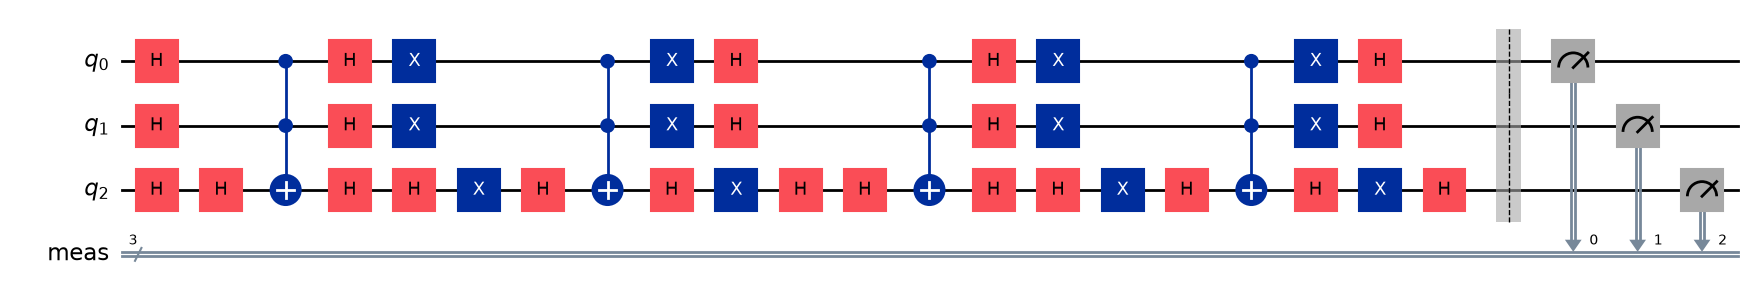

In [4]:
n = 3
iterations = 2

qc = QuantumCircuit(n)

# Initial uniform superposition
qc.h(range(n))

# Oracle: mark |1111111111>
def oracle(qc, n):
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

# Diffusion operator
def diffusion(qc, n):
    qc.h(range(n))
    qc.x(range(n))

    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

    qc.x(range(n))
    qc.h(range(n))

# Grover iterations
for _ in range(iterations):
    oracle(qc, n)
    diffusion(qc, n)

qc.measure_all()

qc.draw('mpl', fold=-1)

In [6]:
decomposer = MitaraiFujiDecomposition(decom_percent=100, epsilon=0.05)
analyser = MPSSimulationAnalyzer(qc, decomposer, n_trajectories=100, max_shots=100_000)
report = analyser.analyze()
print(report.summary())

C:\Users\digvijaya\Projects\hybrid-QPD-MPS-Large-Scale-Quantum-Simulation\qpd_mps\decomposition.py:533: RuntimeWarning: Optimal shots = 2.354e+26; consider cutting fewer gates.
  warnings.warn(f"Optimal shots = {n:.3e}; consider cutting fewer gates.", RuntimeWarning)


Qubits                          : 3
--- MPS (original, uncut) ---
  Max bond dimension            : 2
  Avg bond dimension            : 2.000
  Memory                        : 0.28 KiB
--- MPS (decomposed, 100 trajectories) ---
  Max bond dimension (worst)    : 1
  Max bond dimension (mean±std) : 1.00 ± 0.00
  Avg bond dimension (mean)     : 1.000
  Memory (mean / peak)          : 0.15 / 0.15 KiB
  Bond reduction (max)          : 2.00x
  Memory reduction              : 1.89x
  RSS delta (trajectory loop)   : -54.51 MiB
--- QPD ---
  Cut rotations                 : 24
  kappa                         : 282429536481.0061
  Sampling overhead (kappa^2)   : 7.977e+22
  Optimal shots (eps, delta)    : 235399034395228882029510656
  Shots used                    : 100000  (CAPPED)
--- Observable ---
  Reconstructed estimate        : 2044789844.122458 ± 8.93e+08
  Reference (original circuit)  : -0.9374999999999964
  Abs. error                    : 2.045e+09
  Error in std errors           : 2.2